# Stage 3 - Analysis and Modeling
## Delivered (1) vs Delayed (0)

Candidates are trained on the **train** split and compared on the
**validation** split only. The test split stays untouched until Stage 4.
Returned orders were removed in Stage 2 and are not part of any split.

The authoritative implementation is `mlops_pipeline/model_stage.py` (with MLflow
tracking). This notebook re-fits the same candidates without logging so the
selection can be inspected step by step.

In [1]:
from pathlib import Path
import sys

# Locate the project root (the folder containing mlops_pipeline/) from any notebook folder.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "mlops_pipeline").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
FEATURE_STORE = ROOT / "artifacts" / "feature_store"
REPORTS = ROOT / "artifacts" / "reports"
FIGURES = ROOT / "artifacts" / "notebook_figures"
FIGURES.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

Project root: C:\Users\Vivek Kumar Singh\Downloads\E-Commerce-Shipping-Prediction-main\E-Commerce-Shipping-Prediction-main


In [2]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

from mlops_pipeline.config import PipelineConfig
from mlops_pipeline.model_stage import _candidate_models, _metrics

config = PipelineConfig()
X_train = pd.read_csv(FEATURE_STORE / "X_train.csv")
y_train = pd.read_csv(FEATURE_STORE / "y_train.csv")["binary_target"]
X_val = pd.read_csv(FEATURE_STORE / "X_validation.csv")
y_val = pd.read_csv(FEATURE_STORE / "y_validation.csv")["binary_target"]
print("Train:", X_train.shape, "Validation:", X_val.shape)
print("Train classes (1=Delivered, 0=Delayed):", y_train.value_counts().to_dict())

Train: (28539, 6) Validation: (9514, 6)
Train classes (1=Delivered, 0=Delayed): {1: 24036, 0: 4503}


### 1. Candidate models

* `dummy_majority` - naive baseline that always predicts the majority class prior
* `logistic_regression` - linear, class-balanced
* `random_forest` - non-linear ensemble, class-balanced
* `xgboost` - gradient boosting

In [3]:
results, fitted = [], {}
for name, model in _candidate_models(config.random_state, quick=False).items():
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_val)[:, 1]
    metrics = _metrics(y_val, model.predict(X_val), proba)
    fitted[name] = (model, proba)
    results.append({"model": name, **{k: round(metrics[k], 4) for k in
                    ["roc_auc", "accuracy", "balanced_accuracy", "f1_weighted", "minority_recall", "average_precision_delayed"]}})
comparison = pd.DataFrame(results).sort_values("roc_auc", ascending=False).reset_index(drop=True)
comparison

,model,roc_auc,accuracy,balanced_accuracy,f1_weighted,minority_recall,average_precision_delayed
0,xgboost,0.5078,0.8402,0.4994,0.7695,0.0013,0.1599
1,random_forest,0.5054,0.7748,0.5035,0.7539,0.1073,0.1600
2,logistic_regression,0.5009,0.5045,0.4985,0.5706,0.4897,0.1588
3,dummy_majority,0.5000,0.8422,0.5000,0.7701,0.0000,0.1578


`minority_recall` is the recall of the **Delayed** class (the class the business wants to catch).

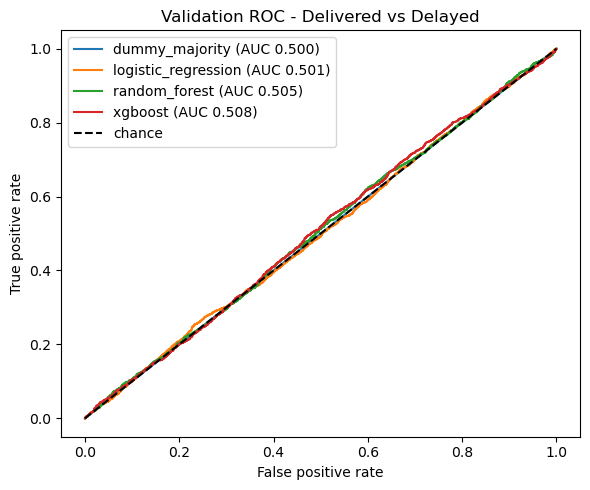

In [4]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, (_, proba) in fitted.items():
    fpr, tpr, _ = roc_curve(y_val, proba)
    auc = comparison.set_index("model").loc[name, "roc_auc"]
    ax.plot(fpr, tpr, label=f"{name} (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", label="chance")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("Validation ROC - Delivered vs Delayed"); ax.legend()
fig.tight_layout(); fig.savefig(FIGURES / "validation_roc.png", dpi=150); plt.show()

### 2. Selection and threshold (validation only)

The candidate with the best validation ROC-AUC (excluding the baseline) is
selected. The decision threshold is then tuned on validation to maximise net
business benefit subject to Delayed recall >= 0.40.

In [5]:
selection = json.loads((REPORTS / "analytical_model_selection.json").read_text(encoding="utf-8"))
notebook_choice = comparison[comparison.model != "dummy_majority"].iloc[0]["model"]
print("Notebook choice:", notebook_choice)
print("Pipeline choice:", selection["selected_model"])
print("Frozen threshold:", selection["validation_selected_threshold"])
print("Threshold status:", selection["threshold_selection"]["status"])
assert notebook_choice == selection["selected_model"]

Notebook choice: xgboost
Pipeline choice: xgboost
Frozen threshold: 0.85
Threshold status: no_economically_viable_threshold_diagnostic_fallback


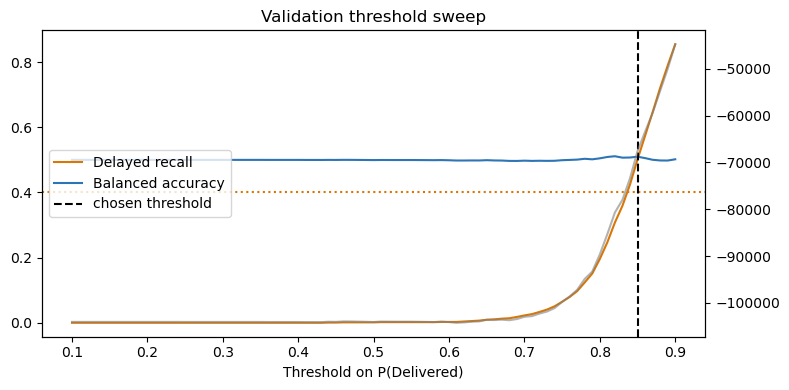

In [6]:
sweep = pd.read_csv(REPORTS / "threshold_sweep_validation.csv")
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(sweep.threshold, sweep.minority_recall, label="Delayed recall", color="#D97706")
ax1.plot(sweep.threshold, sweep.balanced_accuracy, label="Balanced accuracy", color="#2E75B6")
ax1.axhline(config.minimum_minority_recall, color="#D97706", linestyle=":")
ax1.axvline(selection["validation_selected_threshold"], color="black", linestyle="--", label="chosen threshold")
ax2 = ax1.twinx(); ax2.plot(sweep.threshold, sweep.net_benefit_eur, color="grey", alpha=0.6, label="Net benefit (EUR)")
ax1.set_xlabel("Threshold on P(Delivered)"); ax1.set_title("Validation threshold sweep"); ax1.legend(loc="center left")
fig.tight_layout(); fig.savefig(FIGURES / "threshold_sweep.png", dpi=150); plt.show()

### Summary

* All candidates have validation ROC-AUC close to 0.50 (chance level).
* The selected candidate is chosen on validation data only; no test data is used.
* No threshold yields a positive net benefit, so a diagnostic fallback threshold is used.

Next: `evalaution/stage4_evaluation.ipynb` opens the untouched test set once.